# Aula 7 - Estatística Inferencial

Pergunta da aula: quando comparamos dois grupos e encontramos uma diferença, ela é real ou só acaso da amostra?

# 1. Preparando os dados

In [2]:
# importa as bibliotecas e define o tema dos gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="colorblind")

In [3]:
# carrega a base e cria o rótulo do câmbio
# am = 1 significa câmbio manual e am = 0, automático
mtcars = (
  pd.read_csv("data/mtcars.csv")
  .assign(
    # np.where escolhe o rótulo linha a linha: "Manual" se am == 1, senão "Automático"
    transmission=lambda df: np.where(
      df["am"] == 1,
      "Manual",
      "Automático",
    ),
  )
)

mtcars.head()

,model,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb,transmission
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4,Manual
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4,Manual
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1,Manual
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1,Automático
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2,Automático


# 2. A diferença observada
O primeiro passo é descritivo: calcular a média de cada grupo e a distância entre elas, o **efeito observado** (Δobs = média A − média B).

In [4]:
# resumo do consumo (mpg = milhas por galão) em cada tipo de câmbio
# size = quantidade de carros, std = desvio-padrão (o quanto os valores se espalham)
(
  mtcars
  .groupby("transmission")
  .mpg
  .agg(["size", "mean", "median", "std"])
  .round(2)
)

,size,mean,median,std
transmission,,,,
Automático,19,17.15,17.3,3.83
Manual,13,24.39,22.8,6.17


In [5]:
# separa o consumo dos dois grupos
manual = mtcars.loc[mtcars.am == 1, "mpg"]
automatic = mtcars.loc[mtcars.am == 0, "mpg"]

# efeito observado: quanto os manuais fazem a mais, em média
# positivo = manuais mais econômicos
delta_obs = manual.mean() - automatic.mean()

round(delta_obs, 2)

np.float64(7.24)

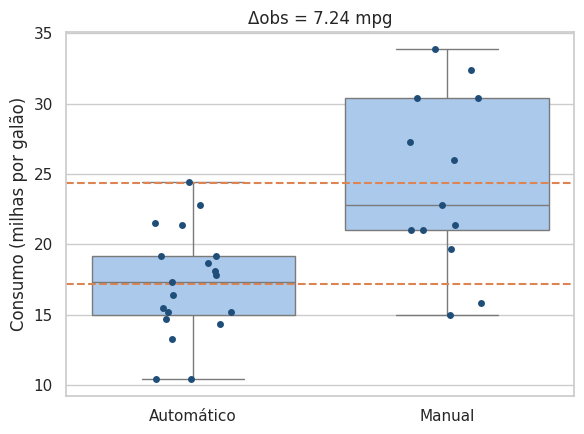

In [6]:
# função reaproveitável: boxplot de cada grupo com os pontos (carros) por cima
def plot_groups(data, x, y, order, ax, alpha=1, jitter=.15):
  sns.boxplot(
    data=data, x=x, y=y, order=order, ax=ax,
    color="#A1C9F4",
    showfliers=False,  # não desenha os outliers, pois o stripplot já mostra todos os pontos
  )
  sns.stripplot(
    data=data, x=x, y=y, order=order, ax=ax,
    color="#1F4E79", alpha=alpha, jitter=jitter,  # alpha = transparência, jitter = espalha os pontos para os lados
  )

fig, ax = plt.subplots(figsize=(6, 4.5))
plot_groups(mtcars, "transmission", "mpg", ["Automático", "Manual"], ax)

# linhas tracejadas na média de cada grupo
for mean in [automatic.mean(), manual.mean()]:
  ax.axhline(mean, color="#DD8452", linestyle="--")
ax.set(title=f"Δobs = {delta_obs:.2f} mpg", xlabel="", ylabel="Consumo (milhas por galão)")

plt.tight_layout()
plt.show()

Os manuais parecem mais econômicos (≈ 7,24 mpg a mais), mas isso só descreve **esta amostra** de 32 carros. Com outros 32 carros a diferença seria outra.

# 3. O problema da aleatoriedade
Apofenia: tendência de enxergar padrões em dados aleatórios. Exemplo: a crença de que "plantão de lua cheia é sempre cheio".

## 3.1 Um pronto-socorro simulado
Simulamos um ano de atendimentos **sem nenhum efeito da lua**. Assim, qualquer diferença que aparecer é puro acaso.

In [7]:
# semente fixa: o sorteio dá sempre o mesmo resultado
rng = np.random.default_rng(2726)

# dias de lua cheia: o ciclo lunar dura ~29,53 dias, então são 12 luas cheias no ano
full_moon_days = np.round(np.arange(12) * 29.53 + 14)

er_visits = (
  pd.DataFrame({"day": np.arange(365)})
  .assign(
    # todos os dias são sorteados da MESMA distribuição de Poisson (média de 120 atendimentos)
    # ou seja, a lua não tem efeito nenhum
    visits=rng.poisson(120, size=365),
    full_moon=lambda df: df["day"].isin(full_moon_days),  # True se o dia é de lua cheia
    moon=lambda df: np.where(df["full_moon"], "Lua cheia", "Demais dias"),
  )
)

In [8]:
# atendimentos por dia em cada grupo (12 dias de lua cheia x 353 demais dias)
(
  er_visits
  .groupby("moon")
  .visits
  .agg(["size", "mean", "median", "std"])
  .round(2)
)

,size,mean,median,std
moon,,,,
Demais dias,353,119.78,119.0,10.94
Lua cheia,12,123.67,121.5,9.36


In [9]:
# atendimentos de cada grupo
moon_in = er_visits.loc[er_visits.full_moon, "visits"]
moon_out = er_visits.loc[~er_visits.full_moon, "visits"]  # inverte: seleciona os dias que NÃO são de lua cheia

# efeito observado da lua cheia
moon_obs = moon_in.mean() - moon_out.mean()

round(moon_obs, 2)

np.float64(3.88)

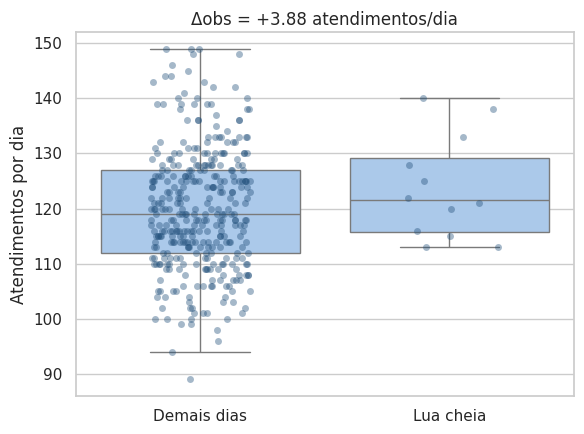

In [10]:
# mesmo boxplot, agora para o pronto-socorro
# com 365 pontos, deixamos os pontos mais transparentes (alpha=.4)
fig, ax = plt.subplots(figsize=(6, 4.5))

plot_groups(
  er_visits, "moon", "visits", ["Demais dias", "Lua cheia"], ax,
  alpha=.4, jitter=.2,
)

ax.set(
  title=f"Δobs = {moon_obs:+.2f} atendimentos/dia",
  xlabel="",
  ylabel="Atendimentos por dia",
)

plt.tight_layout()
plt.show()

A lua cheia teve ≈ 3,9 atendimentos a mais por dia, mesmo sem efeito nenhum: é só acaso. Com só 12 dias, a média da lua cheia oscila muito.
Precisamos de um método que diga se uma diferença é grande em relação ao que o acaso costuma produzir

# 4. Formalizando o acaso
## 4.1 Hipóteses nula e alternativa
- **H₀ (nula):** não existe efeito, Δ = 0.
- **H₁ (alternativa):** existe efeito, Δ ≠ 0 (bilateral: vale nos dois sentidos).

Partimos de H₀, como num tribunal ("inocente até que se prove o contrário"), e só a rejeitamos se os dados forem muito improváveis sob ela.

## 4.2 O teste de permutação
Se H₀ for verdadeira, o rótulo "lua cheia" não significa nada e poderia estar em quaisquer 12 dias. Então:
1. embaralhamos os rótulos;
2. recalculamos a diferença de médias;
3. repetimos milhares de vezes, o que forma a distribuição nula (o que o acaso produz);
4. vemos onde o Δobs cai nessa distribuição.

In [11]:
# distribuição nula por permutação
def permutation_null(values, labels, n_perm=10_000, seed=2026):
  rng = np.random.default_rng(seed)
  null = []
  for _ in range(n_perm):  # _ = variável do laço que não será usada
    # embaralha os rótulos: os valores ficam no lugar, os rótulos mudam de dono
    shuffled = rng.permutation(labels)
    # diferença de médias com os rótulos sorteados
    null.append(values[shuffled].mean() - values[~shuffled].mean())
  return np.array(null)

# converte para arrays do NumPy (indexação booleana mais rápida e sem alinhar índices)
moon_values = er_visits["visits"].to_numpy()
moon_labels = er_visits["full_moon"].to_numpy()

moon_null = permutation_null(moon_values, moon_labels)

# as 5 primeiras diferenças produzidas pelo acaso
moon_null[:5].round(2)

array([-5.33, -6.46, -2.23, -1.54,  4.49])

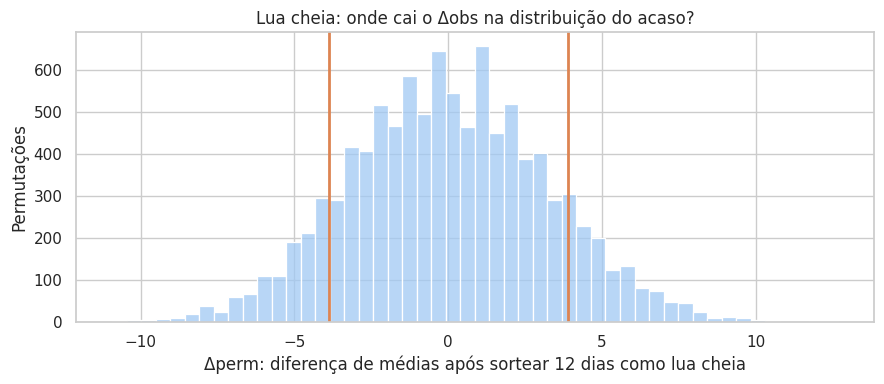

In [12]:
# função reaproveitável: histograma da distribuição nula com o Δobs marcado
def plot_null(null, obs, title, xlabel):
  fig, ax = plt.subplots(figsize=(9, 4))
  sns.histplot(null, bins=50, color="#A1C9F4", ax=ax)
  # marca +Δobs e -Δobs, porque o teste é bilateral
  for value in [-obs, obs]:
      ax.axvline(value, color="#DD8452", linewidth=2)
  ax.set(title=title, xlabel=xlabel, ylabel="Permutações")
  plt.tight_layout()
  plt.show()

plot_null(
  moon_null,
  moon_obs,
  title="Lua cheia: onde cai o Δobs na distribuição do acaso?",
  xlabel="Δperm: diferença de médias após sortear 12 dias como lua cheia",
)

In [13]:
# proporção de permutações tão ou mais extremas que o observado (o p-valor)
# a média de um vetor de True/False é a proporção de True
# abs() conta os dois sentidos, porque o teste é bilateral
moon_p = np.mean(np.abs(moon_null) >= abs(moon_obs))

moon_p

np.float64(0.23)

## 4.3 O p-valor
**p-valor** = probabilidade, **supondo H₀ verdadeira**, de obter um efeito tão ou mais extremo que o observado.

Na lua cheia, p ≈ 0,23: cerca de 1 em cada 4 sorteios de 12 dias dá uma diferença desse tamanho. É um resultado comum sob o acaso.

⚠️ O p-valor **não** é "a probabilidade de H₀ ser verdadeira".

## 4.4 A regra de decisão
Fixamos **antes** da análise um nível de significância α (normalmente 0,05):
- p ≤ α: rejeitamos H₀ (a diferença dificilmente é acaso);
- p > α: não rejeitamos H₀ (os dados são compatíveis com o acaso).

Lua cheia: p ≈ 0,23 > 0,05, então não rejeitamos H₀.

## 4.5 Permutação no mtcars

In [14]:
# mesmo procedimento para o câmbio: embaralha quem é manual e quem é automático
mpg_values = mtcars["mpg"].to_numpy()
mpg_labels = (mtcars["am"] == 1).to_numpy()  # True = manual

mpg_null = permutation_null(mpg_values, mpg_labels)

# p-valor: proporção de permutações tão extremas quanto 7,24 mpg
mpg_p = np.mean(np.abs(mpg_null) >= abs(delta_obs))

mpg_p

np.float64(0.0001)

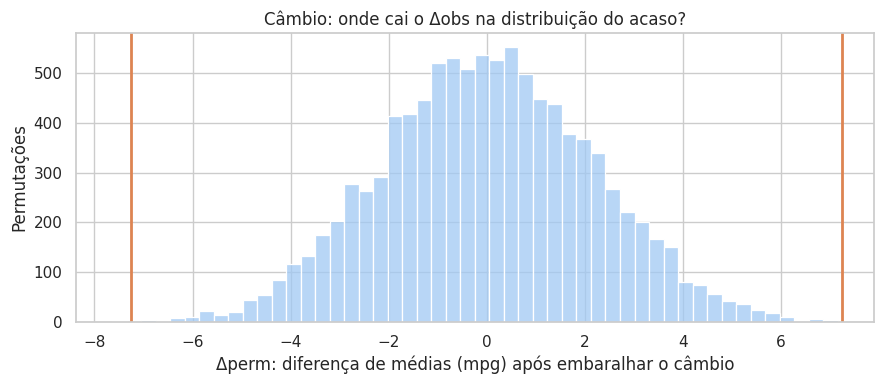

In [15]:
# distribuição nula do câmbio e posição do efeito observado
plot_null(
  mpg_null,
  delta_obs,
  title="Câmbio: onde cai o Δobs na distribuição do acaso?",
  xlabel="Δperm: diferença de médias (mpg) após embaralhar o câmbio",
)

O Δobs cai na ponta da distribuição: só ~1 em 10.000 permutações chegou a 7,24 mpg. Como p < 0,05, **rejeitamos H₀**.
Com 10.000 permutações, o menor p possível é 0,0001, então o correto é reportar "p < 0,001".

⚠️ Rejeitar H₀ diz que a diferença não é acaso, mas **não** prova que o câmbio é a causa.

# 5. O atalho paramétrico
Em vez de simular a distribuição nula, o teste paramétrico **supõe** uma forma para ela (normal / t) e usa uma fórmula. É mais rápido, mas depende de premissas.

## 5.1 O erro-padrão
A largura da distribuição nula mede o quanto a diferença oscila por acaso.

In [16]:
# largura da distribuição nula do câmbio, medida pela simulação (desvio-padrão das permutações)
round(mpg_null.std(), 2)

np.float64(2.16)

In [17]:
# a mesma largura, prevista pela fórmula do erro-padrão: SE = s * raiz(1/nA + 1/nB)
n_manual, n_automatic = len(manual), len(automatic)

# s = desvio-padrão dos 32 carros juntos (sob H₀ os grupos vêm da mesma população)
se_null = mtcars.mpg.std() * np.sqrt(1 / n_manual + 1 / n_automatic)

round(se_null, 2)

np.float64(2.17)

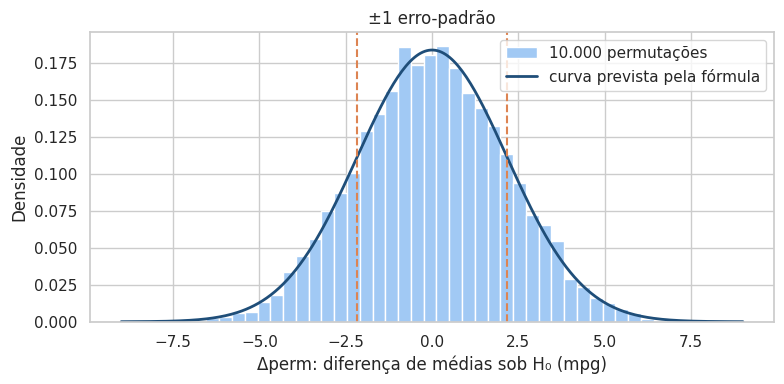

In [18]:
# compara o histograma das permutações com a curva normal prevista pela fórmula
fig, ax = plt.subplots(figsize=(8, 4))

grid = np.linspace(-9, 9, 300)  # 300 pontos entre -9 e 9 para desenhar a curva

# density=True põe o histograma na mesma escala da curva (área total = 1)
ax.hist(mpg_null, bins=40, density=True,
        color="#A1C9F4", label="10.000 permutações")
# curva normal com média 0 e largura igual ao erro-padrão
ax.plot(grid, stats.norm.pdf(grid, 0, se_null),
        color="#1F4E79", linewidth=2, label="curva prevista pela fórmula")

# linhas em -1 e +1 erro-padrão (cerca de 2/3 das permutações ficam entre elas)
for value in [-se_null, se_null]:
    ax.axvline(value, color="#DD8452", linestyle="--")

ax.set(title="±1 erro-padrão", xlabel="Δperm: diferença de médias sob H₀ (mpg)",
       ylabel="Densidade")
ax.legend()

plt.tight_layout()
plt.show()

Simulação (2,16) e fórmula (2,17) praticamente coincidem. Essa largura é o **erro-padrão (SE)**, a "régua do acaso".

## 5.2 Desvio-padrão e erro-padrão
- **Desvio-padrão:** o quanto os **dados** variam. Não muda com o tamanho da amostra.
- **Erro-padrão:** o quanto a **média** varia de uma amostra para outra. Diminui quando a amostra cresce (s / √n).

In [19]:
# sorteia 2.000 amostras de cada tamanho n e compara o desvio-padrão dos dados com o das médias
rng = np.random.default_rng(42)

def sample_summary(n, n_samples=2_000):
  # matriz 2000 x n: cada linha é uma amostra de tamanho n (sorteio com reposição)
  samples = rng.choice(moon_values, size=(n_samples, n))
  return {
    # desvio-padrão dentro de cada amostra, depois a média entre as amostras
    "dp_dos_dados": samples.std(axis=1, ddof=1).mean(),
    # desvio-padrão das 2.000 médias amostrais = erro-padrão observado
    "dp_das_medias": samples.mean(axis=1).std(ddof=1),
    # erro-padrão previsto pela fórmula s / raiz(n)
    "previsto_s_raiz_n": moon_values.std(ddof=1) / np.sqrt(n),
  }

(
  pd.DataFrame({n: sample_summary(n) for n in [10, 40, 160, 640]})
  .T  # transpõe: cada linha passa a ser um tamanho de amostra
  .rename_axis("n")
  .round(2)
)

,dp_dos_dados,dp_das_medias,previsto_s_raiz_n
n,,,
10,10.64,3.54,3.45
40,10.81,1.63,1.72
160,10.87,0.89,0.86
640,10.89,0.42,0.43


Note que `dp_dos_dados` fica parado (~11) e `dp_das_medias` cai à medida que n cresce, como a fórmula prevê.

## 5.3 A estatística t
**t = Δobs / SE**: quantos erros-padrão cabem entre 0 e a diferença observada. Sob o acaso, t quase nunca passa de 2.

In [20]:
# efeito observado do câmbio medido em erros-padrão
round(delta_obs / se_null, 2)

np.float64(3.34)

In [21]:
# versão de Welch: estima a variância de cada grupo separadamente (não exige variâncias iguais)
se_welch = np.sqrt(manual.var() / n_manual + automatic.var() / n_automatic)

# (erro-padrão de Welch, estatística t de Welch)
round(se_welch, 2), round(delta_obs / se_welch, 2)

(np.float64(1.92), np.float64(3.77))

O teste t transforma o valor de t em p-valor usando a **distribuição t**, que tem caudas mais pesadas que a normal quando há poucos **graus de liberdade** (pouca informação). O `stats.ttest_ind` faz tudo isso de uma vez.

In [22]:
# teste t de Welch no mtcars
# equal_var=False = versão de Welch; com True seria o teste t clássico (variâncias iguais)
mpg_ttest = stats.ttest_ind(manual, automatic, equal_var=False)

mpg_ttest  # mostra a estatística t, o p-valor e os graus de liberdade (df)

TtestResult(statistic=np.float64(3.767123145144923), pvalue=np.float64(0.0013736383330710345), df=np.float64(18.332251638400464))

In [23]:
# teste t de Welch na lua cheia
moon_ttest = stats.ttest_ind(moon_in, moon_out, equal_var=False)

moon_ttest

TtestResult(statistic=np.float64(1.4048153658505091), pvalue=np.float64(0.1853402601391711), df=np.float64(12.043510826046889))

Mesmas conclusões da permutação: mtcars p < 0,05 (rejeita H₀); lua cheia p ≈ 0,19 > 0,05 (não rejeita).

## 5.4 Premissas e limitações do teste t
O teste t supõe observações independentes e diferença de médias aproximadamente normal. Ele compara **médias** e por isso é sensível a valores atípicos.

## 5.5 Um único valor atípico muda a história

In [24]:
# adiciona um carro automático com consumo digitado errado: 60 mpg
automatic_typo = pd.concat(
    [automatic, pd.Series([60.])],
    ignore_index=True,  # refaz o índice de 0 a n-1
)

In [25]:
# reúne as medidas que o valor atípico pode afetar
def compare(group_a, group_b):
  test = stats.ttest_ind(group_a, group_b, equal_var=False)
  return {
    "dif_medias": group_a.mean() - group_b.mean(),
    "dif_medianas": group_a.median() - group_b.median(),
    "dp_automaticos": group_b.std(),
    "t": test.statistic,
    "p": test.pvalue,
  }

In [26]:
# compara a base original com a base com o erro de digitação
(
  pd.DataFrame(
    {
      "mtcars original": compare(manual, automatic),
      "+1 automático com 60 mpg": compare(manual, automatic_typo),
    }
  )
  .T
  .round(4)
)

,dif_medias,dif_medianas,dp_automaticos,t,p
mtcars original,7.2449,5.50,3.8340,3.7671,0.0014
+1 automático com 60 mpg,5.1023,5.25,10.2831,1.7805,0.0848


Um único valor errado diminui a diferença de médias **e** aumenta o desvio-padrão, então o t cai e o teste deixa de rejeitar H₀. A diferença de **medianas** quase não muda (5,50 → 5,25).
👉 Olhe boxplots antes de testar.

## 5.6 Permutação e teste t

In [27]:
# p-valores dos dois métodos nos dois exemplos
(
  pd.DataFrame(
    {
      "permutação": [mpg_p, moon_p],
      "teste t (Welch)": [mpg_ttest.pvalue, moon_ttest.pvalue],
    },
    index=["mtcars", "Lua cheia"],
  )
  .round(4)
)

,permutação,teste t (Welch)
mtcars,0.0001,0.0014
Lua cheia,0.2300,0.1853


Os valores não são idênticos, mas as **decisões** coincidem nos dois exemplos.

# 6. Armadilhas da decisão
## 6.1 Dois tipos de erro
- **Erro tipo I (falso positivo):** rejeitar H₀ quando ela é verdadeira. A taxa desse erro é α.
- **Erro tipo II (falso negativo):** não rejeitar H₀ quando existe efeito. **Poder** = 1 − β = chance de detectar um efeito real; cresce com o tamanho do efeito e com n.

## 6.2 Muitos testes
Quanto mais testes fazemos, mais falsos positivos aparecem por acaso.

In [28]:
# simula 20 pronto-socorros, todos SEM efeito da lua
rng = np.random.default_rng(7)

# cada linha é um hospital: 12 dias de lua cheia x 353 demais dias
# axis=1 faz um teste t por linha, devolvendo 20 p-valores
hospital_p = stats.ttest_ind(
  rng.poisson(120, size=(20, 12)),
  rng.poisson(120, size=(20, 353)),
  axis=1,
  equal_var=False,
).pvalue

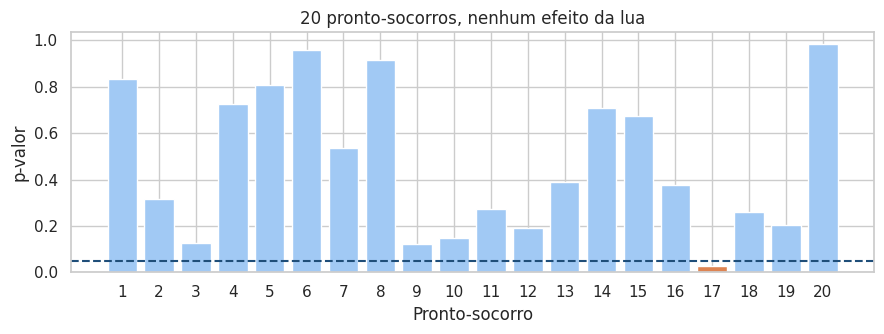

In [29]:
# p-valor de cada pronto-socorro; laranja = rejeitou H₀ (p <= 0,05)
fig, ax = plt.subplots(figsize=(9, 3.5))

ax.bar(
  np.arange(1, 21),
  hospital_p,
  color=np.where(hospital_p <= .05, "#DD8452", "#A1C9F4"),
)
ax.axhline(.05, color="#1F4E79", linestyle="--")  # limiar α = 0,05
ax.set(
  title="20 pronto-socorros, nenhum efeito da lua",
  xlabel="Pronto-socorro",
  ylabel="p-valor",
  xticks=np.arange(1, 21),
)

plt.tight_layout()
plt.show()

Um "alarme falso" em 20 é exatamente o que α = 0,05 prevê. A chance de **pelo menos um** falso positivo em k testes é 1 − (1 − α)ᵏ.
A **correção de Bonferroni** usa α/k como limiar em cada teste.

In [30]:
# probabilidade de pelo menos um falso positivo em k testes sem efeito
alpha = .05

(
  pd.DataFrame({"k": [1, 5, 20, 100]})
  .assign(
    sem_correcao=lambda df: 1 - (1 - alpha) ** df["k"],
    # Bonferroni: cada teste usa o limiar α/k (com 20 testes, 0,0025)
    bonferroni=lambda df: 1 - (1 - alpha / df["k"]) ** df["k"],
  )
  .set_index("k")
  .round(3)
)

,sem_correcao,bonferroni
k,,
1,0.050,0.050
5,0.226,0.049
20,0.642,0.049
100,0.994,0.049


Testar muitas coisas e relatar só o que deu p < 0,05 é **p-hacking**.

## 6.3 Significância estatística não é relevância prática
Com amostras enormes, até efeitos minúsculos ficam "significantes", porque t ≈ d·√(n/2) cresce com n.

In [31]:
# p-valor de um efeito minúsculo e FIXO (0,02 desvio-padrão) para tamanhos de grupo crescentes
(
  pd.Series(
    {
      # .02 * raiz(n/2) é a estatística t; stats.t.sf dá a área da cauda direita
      # multiplicamos por 2 porque o teste é bilateral
      n: 2 * stats.t.sf(.02 * np.sqrt(n / 2), df=2 * n - 2)
      for n in [100, 1_000, 10_000, 100_000, 1_000_000]
    },
    name="p",
  )
  .rename_axis("n por grupo")
  .to_frame()
)

,p
n por grupo,
100,8.876809e-01
1000,6.547693e-01
10000,1.573148e-01
100000,7.748470e-06
1000000,2.099060e-45


O efeito é o mesmo em todas as linhas; só o n mudou. Por isso, além do p-valor, reporte o **tamanho do efeito**, como o **d de Cohen** = diferença de médias / desvio-padrão combinado (≈ 0,2 pequeno, 0,5 médio, 0,8 grande). No mtcars, d ≈ 1,48, um efeito grande. 

Em síntese, um efeito é "real" quando seria improvável sob o acaso (p-valor pequeno). E só importa se for grande (tamanho do efeito) e não for explicado por outra variável (confundidor).

# 7. Questões para casa


1. Adapte permutation_null para usar a diferença de medianas. Aplique-a ao cenário com o automático de 60 mpg e compare o p-valor com o do teste t da seção 5.5.

In [32]:
# Distribuição nula por permutação, aplicada à lua cheia
def permutation_null(values, labels, n_perm=10_000, seed=2026):
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_perm):
        shuffled = rng.permutation(labels)
        # arrays do NumPy não têm o método .median(), por isso usamos np.median()
        null.append(np.median(values[shuffled]) - np.median(values[~shuffled]))
    return np.array(null)

automatic_typo = pd.concat(
  [automatic, pd.Series([60.])],
  ignore_index=True,
)

# Diferenças, dispersão e teste t, sem e com o valor digitado errado
def compare(group_a, group_b):
    test = stats.ttest_ind(group_a, group_b, equal_var=False)
    return {
        "dif_medias": group_a.mean() - group_b.mean(),
        "dif_medianas": group_a.median() - group_b.median(),
        "dp_automaticos": group_b.std(),
        "t": test.statistic,
        "p": test.pvalue,
    }


(
    pd.DataFrame(
        {
            "mtcars original": compare(manual, automatic),
            "+1 automático com 60 mpg": compare(manual, automatic_typo),
        }
    )
    .T
    .round(4)
)

,dif_medias,dif_medianas,dp_automaticos,t,p
mtcars original,7.2449,5.50,3.8340,3.7671,0.0014
+1 automático com 60 mpg,5.1023,5.25,10.2831,1.7805,0.0848


In [33]:
# junta os consumos dos manuais com os dos automáticos COM o carro de 60 mpg
typo_values = np.concatenate([manual.to_numpy(), automatic_typo.to_numpy()])
# rótulos: True = manual, False = automático (na mesma ordem dos valores)
typo_labels = np.concatenate([
    np.ones(len(manual), dtype=bool),
    np.zeros(len(automatic_typo), dtype=bool),
])

# efeito observado agora é a diferença de MEDIANAS
median_obs = manual.median() - automatic_typo.median()

# distribuição nula da diferença de medianas e p-valor bilateral
median_null = permutation_null(typo_values, typo_labels)
median_p = np.mean(np.abs(median_null) >= abs(median_obs))

round(median_obs, 2), median_p

(np.float64(5.25), np.float64(0.0228))

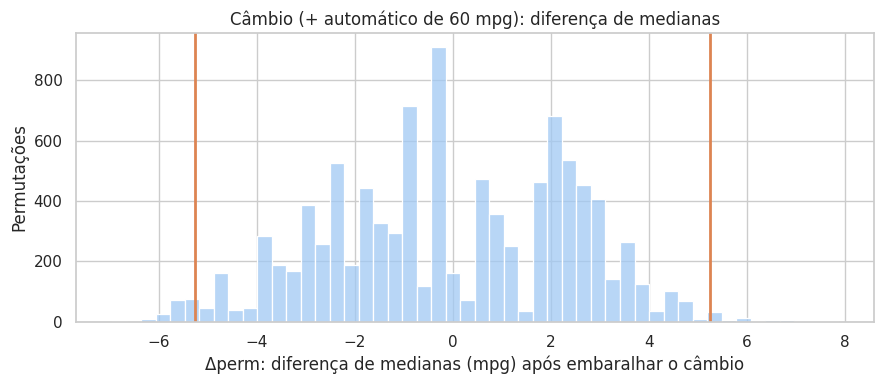

In [34]:
# onde cai a diferença de medianas observada na distribuição do acaso?
plot_null(
  median_null,
  median_obs,
  title="Câmbio (+ automático de 60 mpg): diferença de medianas",
  xlabel="Δperm: diferença de medianas (mpg) após embaralhar o câmbio",
)

In [35]:
# teste t de Welch com o carro de 60 mpg (o mesmo da seção 5.5)
typo_ttest = stats.ttest_ind(manual, automatic_typo, equal_var=False)

# compara os dois p-valores
pd.DataFrame(
    {
        "efeito observado": [median_obs, manual.mean() - automatic_typo.mean()],
        "p-valor": [median_p, typo_ttest.pvalue],
    },
    index=["permutação (medianas)", "teste t de Welch (médias)"],
).round(4)

,efeito observado,p-valor
permutação (medianas),5.2500,0.0228
teste t de Welch (médias),5.1023,0.0848


**Resposta da questão 1**

Com o automático de 60 mpg na base, os dois métodos chegam a conclusões diferentes:

| método | efeito observado | p-valor | rejeita H₀ (α = 0,05)? |
|---|---|---|---|
| permutação com diferença de medianas | 5,25 mpg | ≈ 0,023 | sim |
| teste t de Welch (diferença de médias) | 5,10 mpg | ≈ 0,085 | não |

 O teste t usa a média e o desvio-padrão, e as duas medidas são muito sensíveis a valores extremos. O carro de 60 mpg puxa a média dos automáticos para cima, de 17,1 para 19,3, e isso diminui a diferença entre os grupos. Ele também aumenta muito o desvio-padrão dos automáticos, de 3,8 para 10,3. Como o erro-padrão fica maior, a estatística t cai de 3,77 para 1,78, e o p-valor sobe de 0,001 para 0,085. Assim, um único erro de digitação "apaga" um efeito que era claro.

A mediana é robusta: um valor extremo conta só como "mais um carro acima do meio", não importa se ele tem 25 ou 60 mpg. Por isso a mediana dos automáticos quase não muda (17,3 → 17,55), e a diferença de medianas continua grande (5,5 → 5,25 mpg). O teste por permutação também não supõe distribuição normal, então ele continua detectando o efeito (p ≈ 0,023).

quando os dados têm outliers, um teste baseado na mediana é mais confiável do que o teste t. 

Observação: o p-valor da mediana sem o outlier era ≈ 0,016, então mesmo sem o erro ele é um pouco maior que o do teste t (0,001). A mediana usa menos informação do que a média, então perde um pouco de poder quando os dados são "bem comportados".

2. Na base de imóveis da Aula 6, compare o aluguel de imóveis mobiliados e não mobiliados. Calcule Δobs e o p-valor por permutação e pelo teste t. Repita a análise com o log do aluguel e discuta as diferenças.

In [36]:
# carrega a base de imóveis da Aula 6 (está na pasta da Aula 6)
imoveis = (
  pd.read_csv("../Aula_06/data/imoveis_sao_paulo.csv")
  .rename(columns={"rent amount (R$)": "rent"})
  .assign(
    log_rent=lambda df: np.log(df["rent"]),               # log do aluguel (não há aluguel zero, então o log simples funciona)
    furnished=lambda df: df["furniture"] == "furnished",  # True = mobiliado
  )
)

# resumo do aluguel em cada grupo; skew = assimetria (0 = simétrico)
(
  imoveis
  .groupby("furniture")
  .rent
  .agg(["size", "mean", "median", "std", "skew"])
  .round(2)
)

,size,mean,median,std,skew
furniture,,,,,
furnished,10274,4400.02,3200.0,3774.45,2.22
not furnished,19432,3847.77,2740.0,3439.09,2.27


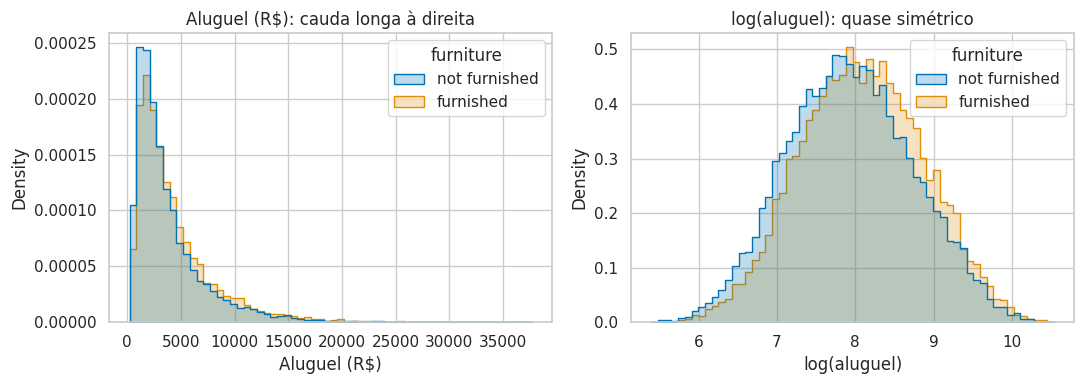

In [37]:
# histogramas do aluguel nas duas escalas, separados por mobília
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# common_norm=False: cada grupo soma área 1, para comparar formas mesmo com tamanhos diferentes
sns.histplot(data=imoveis, x="rent", hue="furniture", bins=60,
             stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set(title="Aluguel (R$): cauda longa à direita", xlabel="Aluguel (R$)")

sns.histplot(data=imoveis, x="log_rent", hue="furniture", bins=60,
             stat="density", common_norm=False, element="step", ax=axes[1])
axes[1].set(title="log(aluguel): quase simétrico", xlabel="log(aluguel)")

plt.tight_layout()
plt.show()

In [38]:
# a função permutation_null foi alterada na questão 1 para usar medianas,
# então recriamos aqui a versão original, com diferença de MÉDIAS
def permutation_mean_null(values, labels, n_perm=10_000, seed=2026):
  rng = np.random.default_rng(seed)
  null = []
  for _ in range(n_perm):
    shuffled = rng.permutation(labels)
    null.append(values[shuffled].mean() - values[~shuffled].mean())
  return np.array(null)

# aplica o mesmo procedimento da aula a uma coluna: Δobs, permutação e teste t
def furniture_test(column, n_perm=10_000):
  values = imoveis[column].to_numpy()
  labels = imoveis["furnished"].to_numpy()

  obs = values[labels].mean() - values[~labels].mean()  # mobiliado - não mobiliado
  null = permutation_mean_null(values, labels, n_perm=n_perm)
  ttest = stats.ttest_ind(values[labels], values[~labels], equal_var=False)

  return {
    "delta_obs": obs,
    "dp_nula": null.std(),                # largura da distribuição do acaso
    "maior_abs_perm": np.abs(null).max(), # o maior efeito que o acaso produziu
    "p_permutacao": np.mean(np.abs(null) >= abs(obs)),
    "t": ttest.statistic,
    "p_teste_t": ttest.pvalue,
    # d de Cohen: diferença de médias medida em desvios-padrão
    "d_cohen": obs / np.sqrt((values[labels].var() + values[~labels].var()) / 2),
  }

# demora alguns segundos: são 10.000 permutações de quase 30 mil imóveis
furniture_results = pd.DataFrame(
  {
    "aluguel (R$)": furniture_test("rent"),
    "log(aluguel)": furniture_test("log_rent"),
  }
).T

furniture_results

,delta_obs,dp_nula,maior_abs_perm,p_permutacao,t,p_teste_t,d_cohen
aluguel (R$),552.252180,43.055996,188.784226,0.0,12.363265,5.602795e-35,0.152956
log(aluguel),0.151576,0.009694,0.043846,0.0,15.710910,2.601478e-55,0.190985


In [ ]:
# o Δobs no log é uma diferença de logs exp() transforma em razão entre os aluguéis
round(np.exp(furniture_results.loc["log(aluguel)", "delta_obs"]), 3)

np.float64(1.164)

3. Ainda na base de imóveis, a diferença de aluguel entre mobiliados e não mobiliados poderia ser explicada por outra variável? Proponha um confundidor e verifique sua hipótese com um gráfico.

In [ ]:
# um confundidor precisa afetar o aluguel e ser diferente entre mobiliados e não mobiliados
# a área está ligada ao aluguel? (Spearman, porque as duas variáveis são assimétricas)
print("Spearman área x aluguel:", round(imoveis["area"].corr(imoveis["rent"], method="spearman"), 2))

# os mobiliados são maiores, têm mais quartos/vagas ou ficam mais perto do transporte?
(
  imoveis
  .groupby("furniture")[["area", "rooms", "parking spaces", "transit_distance_min"]]
  .median()
)

Spearman área x aluguel: 0.73


,area,rooms,parking spaces,transit_distance_min
furniture,,,,
furnished,75.9,2.0,1.0,38.0
not furnished,75.7,2.0,1.0,37.0


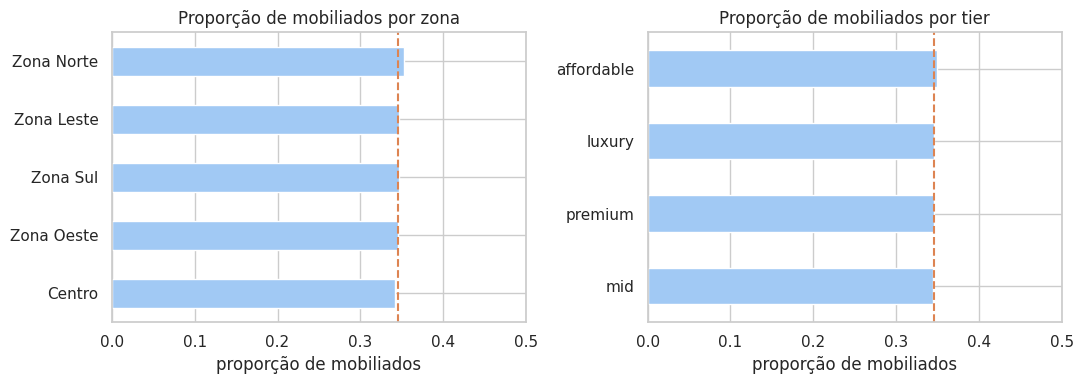

In [ ]:
# a proporção de mobiliados muda com a zona ou com o padrão (tier) do imóvel?
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, column in zip(axes, ["zona", "tier"]):
  share = imoveis.groupby(column)["furnished"].mean().sort_values()  # média de True/False = proporção
  share.plot.barh(ax=ax, color="#A1C9F4")
  ax.axvline(imoveis["furnished"].mean(), color="#DD8452", linestyle="--")  # proporção geral
  ax.set(title=f"Proporção de mobiliados por {column}", xlabel="proporção de mobiliados",
         ylabel="", xlim=(0, .5))

plt.tight_layout()
plt.show()

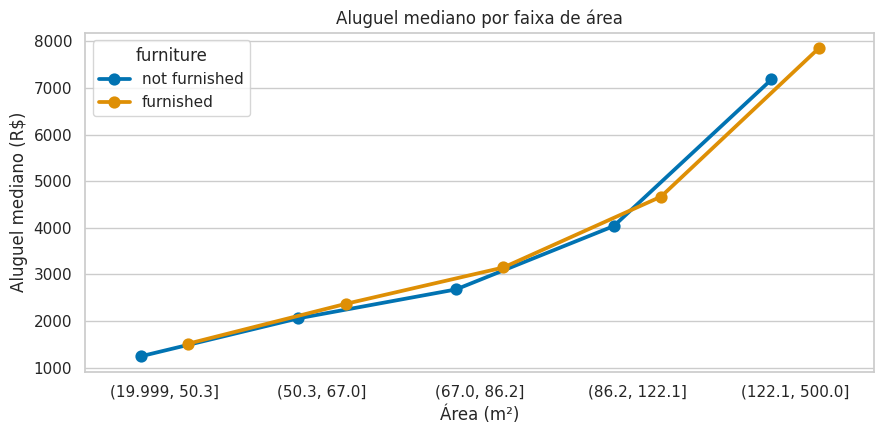

furniture,furnished,not furnished,razao
faixa_area,,,
"(19.999, 50.3]",1515.00,1245.00,1.22
"(50.3, 67.0]",2370.00,2060.00,1.15
"(67.0, 86.2]",3150.00,2680.00,1.18
"(86.2, 122.1]",4670.00,4038.14,1.16
"(122.1, 500.0]",7851.17,7180.96,1.09


In [42]:
# verificação final: comparar mobiliados x não mobiliados DENTRO de faixas de área
# se a área fosse o confundidor, a diferença sumiria dentro de cada faixa
imoveis["faixa_area"] = pd.qcut(imoveis["area"], 5)  # 5 faixas com o mesmo número de imóveis

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.pointplot(
  data=imoveis, x="faixa_area", y="rent", hue="furniture",
  estimator="median", errorbar=None, dodge=.3, ax=ax,
)
ax.set(title="Aluguel mediano por faixa de área", xlabel="Área (m²)", ylabel="Aluguel mediano (R$)")
plt.tight_layout()
plt.show()

# razão entre os aluguéis medianos em cada faixa (1,15 = mobiliado 15% mais caro)
(
  imoveis
  .groupby(["faixa_area", "furniture"], observed=True)["rent"]
  .median()
  .unstack()
  .assign(razao=lambda df: df["furnished"] / df["not furnished"])
  .round(2)
)

**Resposta da questão 3**

Confundidor proposto será a área do imóvel (e junto dela a localização: zona e tier). A hipótese é que talvez os mobiliados sejam imóveis maiores ou mais bem localizados, e por isso seriam mais caros, não por causa da mobília. Para a área ser um confundidor, ela precisa cumprir duas condições:

1. Afetar o aluguel: sim. A correlação de Spearman entre área e aluguel é ≈ 0,73, bem forte.
2. Ser diferente entre os grupos: não. A área mediana é praticamente igual (75,9 m² nos mobiliados contra 75,7 m² nos não mobiliados) e o mesmo vale para quartos, vagas e distância ao transporte. Nos gráficos de barras, a proporção de mobiliados fica em torno de 34–35% em todas as zonas e em todos os tiers.


Nesta base, as variáveis observadas (área, quartos, vagas, zona e tier) não explicam a diferença, porque estão distribuídas da mesma forma nos dois grupos. Por isso a diferença por mobília se mantém mesmo quando comparamos imóveis parecidos. Isso não prova que a mobília causa o aumento, ainda pode existir um confundidor não medido na base, como o estado de conservação, uma reforma recente ou o perfil do locador (por exemplo, imóveis de aluguel por temporada). Para afirmar causalidade de verdade, seria preciso um experimento ou dados sobre essas variáveis. Mas, entre os candidatos que conseguimos verificar, nenhum explica o efeito.